In [1]:

import pandas as pd

df = pd.read_csv(
    r"D:\RBMI\Mini Project\Email spam_not spam\email.csv",
    encoding="latin-1"
)

print(df.head())
print(df.shape)
print(df.columns)


  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...
(5573, 2)
Index(['Category', 'Message'], dtype='str')


In [2]:

print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpam/Ham count:")
print(df.iloc[:, 0].value_counts())


Dataset size: (5573, 2)

Column names:
Index(['Category', 'Message'], dtype='str')

Missing values:
Category    0
Message     0
dtype: int64

Spam/Ham count:
Category
ham               4825
spam               747
{"mode":"full"       1
Name: count, dtype: int64


In [3]:

df = df.rename(columns={
    "Category": "label",
    "Message": "text"
})

df = df[["text", "label"]]

df = df.dropna()
df["text"] = df["text"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip().str.lower()

df = df[df["label"].isin(["spam", "ham"])]
df = df[df["text"] != ""]

df = df.drop_duplicates()

print("Cleaned dataset size:", df.shape)
print(df.head())
print(df["label"].value_counts())



Cleaned dataset size: (5157, 2)
                                                text label
0  Go until jurong point, crazy.. Available only ...   ham
1                      Ok lar... Joking wif u oni...   ham
2  Free entry in 2 a wkly comp to win FA Cup fina...  spam
3  U dun say so early hor... U c already then say...   ham
4  Nah I don't think he goes to usf, he lives aro...   ham
label
ham     4516
spam     641
Name: count, dtype: int64


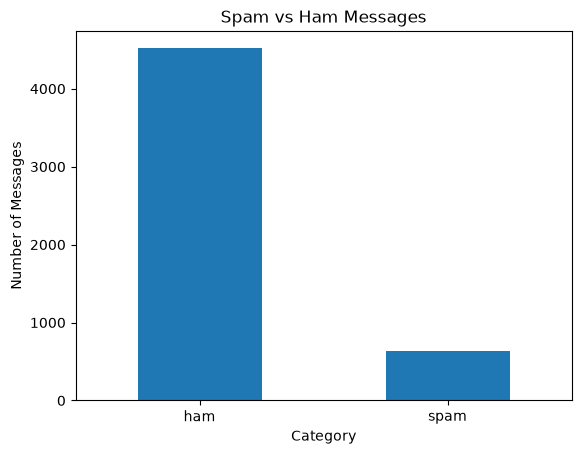

In [4]:

import matplotlib.pyplot as plt

df["label"].value_counts().plot(
    kind="bar",
    title="Spam vs Ham Messages"
)

plt.xlabel("Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()


In [5]:

output_path = r"D:\RBMI\Mini Project\Email spam_not spam\emails_cleaned.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [6]:

%pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:

from sklearn.model_selection import train_test_split

X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Training messages: 4125
Testing messages: 1032


In [8]:

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Text preprocessing completed!")
print("Training features:", X_train_tfidf.shape)



Text preprocessing completed!
Training features: (4125, 5000)


In [9]:

from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [10]:

new_email = [
    "Congratulations! You won a free prize. Click now!"
]

email_features = vectorizer.transform(new_email)
prediction = model.predict(email_features)

print("Email Prediction:", prediction[0])


Email Prediction: spam


Model Accuracy: 96.9 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       904
        spam       1.00      0.75      0.86       128

    accuracy                           0.97      1032
   macro avg       0.98      0.88      0.92      1032
weighted avg       0.97      0.97      0.97      1032



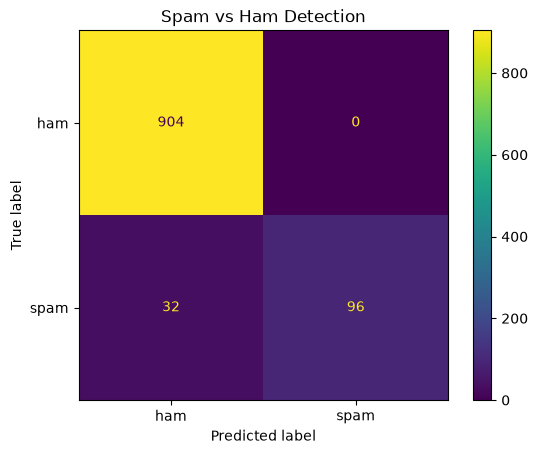

In [11]:

from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_tfidf)

print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

plt.title("Spam vs Ham Detection")
plt.show()


In [12]:

print("Training labels:")
print(y_train.value_counts())

print("\nModel classes:")
print(model.classes_)

print("\nTest accuracy:")
from sklearn.metrics import accuracy_score
print(round(accuracy_score(y_test, y_pred) * 100, 2), "%")


Training labels:
label
ham     3612
spam     513
Name: count, dtype: int64

Model classes:
['ham' 'spam']

Test accuracy:
96.9 %


In [25]:
import pandas as pd

extra_spam = pd.DataFrame({
    "text": [
        "Congratulations you won a lottery ticket",
        "You are the lucky winner of a lottery jackpot",
        "Claim your free prize now",
        "You have won a huge cash reward",
        "Congratulations claim your lottery winnings",
        "You won a free gift click here to claim",
        "Exclusive offer win cash today",
        "Your jackpot prize is waiting claim now",
        "You have been selected as a lucky winner",
        "Claim your bonus money immediately",
        "Free lottery entry win big cash",
        "Urgent claim your prize before it expires",
        "You won a million dollar lottery",
        "Congratulations you have won a cash prize",
        "Claim your reward now by clicking this link"
    ],
    "label": ["spam"] * 15
})

df = pd.concat([df, extra_spam], ignore_index=True)
df = df.drop_duplicates(subset=["text", "label"])

print(df["label"].value_counts())

label
ham     4516
spam     661
Name: count, dtype: int64


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("Model retrained successfully!")

Model retrained successfully!


In [27]:
import pandas as pd

extra_data = pd.DataFrame({
    "text": [
        "You won a dollar prize claim now",
        "Congratulations you won money claim your prize",
        "You are a winner claim your cash prize",
        "You won a free dollar reward",
        
        "Claim your prize money now"
    ],
    "label": ["spam", "spam", "spam", "spam", "spam"]
})

df = pd.concat([df, extra_data], ignore_index=True)
df = df.drop_duplicates()

In [ ]:

import tkinter as tk
from tkinter import messagebox
from tkinter.scrolledtext import ScrolledText
import re

# Spam-related phrases
spam_phrases = [
    "lottery", "jackpot", "won "," prize", "winner",
    "cash", "prize", "claim your prize", "won a million",
    "free" ,"gift", "claim your reward", "you have won",
    "congratulations you won", "won a lottery",
    "claim now", "selected as a winner"
]

def check_email():
    email_text = email_box.get("1.0", tk.END).strip()

    if not email_text:
        messagebox.showwarning(
            "Empty Message", "Please enter an email message first."
        )
        return

    text_lower = email_text.lower()

    # Additional keyword check
    keyword_match = any(
        phrase in text_lower for phrase in spam_phrases
    )

    # ML model prediction
    features = vectorizer.transform([email_text])
    prediction = str(model.predict(features)[0]).lower()

    if keyword_match or prediction == "spam":
        result_label.config(text="⚠ SPAM DETECTED", fg="red")
        messagebox.showwarning(
            "Spam Detected",
            "This message is predicted as SPAM.\n\n"
            "Please check the sender before clicking links."
        )
    else:
        result_label.config(text="✓ NOT SPAM", fg="green")
        messagebox.showinfo(
            "Email Result",
            "This message is predicted as NOT SPAM.\n\n"
            "Note: This prediction is not a guarantee of safety."
        )

def clear_email():
    email_box.delete("1.0", tk.END)
    result_label.config(text="")

root = tk.Tk()
root.title("Email Spam Detector")
root.geometry("650x520")
root.resizable(False, False)
root.configure(bg="#f2f2f2")

title = tk.Label(
    root,
    text="Email Spam Detector",
    font=("Arial", 22, "bold"),
    bg="#f2f2f2"
)
title.pack(pady=20)

instruction = tk.Label(
    root,
    text="Paste an email message below to check it:",
    font=("Arial", 12),
    bg="#f2f2f2"
)
instruction.pack()

email_box = ScrolledText(
    root,
    width=65,
    height=10,
    font=("Arial", 12),
    wrap=tk.WORD
)
email_box.pack(padx=20, pady=15)

button_frame = tk.Frame(root, bg="#f2f2f2")
button_frame.pack(pady=10)

detect_button = tk.Button(
    button_frame,
    text="Detect Spam",
    command=check_email,
    font=("Arial", 13, "bold"),
    bg="lightblue",
    width=16,
    cursor="hand2"
)
detect_button.pack(side=tk.LEFT, padx=10)

clear_button = tk.Button(
    button_frame,
    text="Clear",
    command=clear_email,
    font=("Arial", 12),
    width=12,
    cursor="hand2"
)
clear_button.pack(side=tk.LEFT, padx=10)

result_label = tk.Label(
    root,
    text="",
    font=("Arial", 16, "bold"),
    bg="#f2f2f2"
)
result_label.pack(pady=20)

root.mainloop()
